## `model_analysis.ipynb`

This file is used to perform the analyses including in Figures 4 and 5 of the paper.

## Settings

In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import colorsys # define colors in HLS

# Stats packages
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy.stats import linregress
from scipy.stats import ks_2samp, levene

# Misc
import warnings
import sys
import os
from IPython.display import display

import testis_model as tm

In [2]:
small_label_settings = {
    'font.family': 'Arial',
    'font.size': 7,              # base font size
    'xtick.labelsize': 5,        # x-axis tick label size
    'ytick.labelsize': 5,        # y-axis tick label size
    'axes.labelsize': 7,         # axis label size
    'axes.titlesize': 7,         # title size
    'legend.fontsize': 7,        # legend font size
    'figure.titlesize': 7        # figure title size
}

In [3]:
def hue(r):
    """
    This function inputs a drift rate `r` and outputs a shade of blue.
    Lower values of `r` correspond to darker shades.

    This function is used to make colors consistent across the figures.
    """
    lamb = (symlog10(r) - symlog10(0)) / (symlog10(36) - symlog10(0))
    return colorsys.hls_to_rgb(0.5, 0.30 + 0.45 * lamb, 0.5)

exp_hue = '#ffc566'

In [4]:
def symlog10(x, linthresh=1e-2):
    return np.sign(x) * np.log10(1 + np.abs(x) / linthresh)

def inv_symlog10(y, linthresh=1e-2):
    return np.sign(y) * ((10**np.abs(y) - 1) * linthresh)

## Load in data

In [5]:
file_path = os.path.join('..', 'model_simulations', 'all_clone_results.csv')
df = pd.read_csv(file_path)

exp_scenario = 'full_pipeline'

invalid_real_entries = df.query('scenario == @exp_scenario').query('n_transient < 2')
if len(invalid_real_entries) > 0:
    print(f'There are {len(invalid_real_entries)} real clones that have < 2 observation times.')

# Only include data that has at least 2 observations and are not trivial.
df = df.query('n_transient > 1').copy()

print(f'The loaded clone data has {len(df)} rows.')

There are 3 real clones that have < 2 observation times.
The loaded clone data has 43285 rows.


In [6]:
# Compute additional columns 

df['l_gap'] = df['l_max'] - df['l_null']

# Test statistic 4 (or a log likelihood difference of 2) corresponds to
# an alpha=0.05 signifiance level.
df['pass_null'] = df['l_gap'] > 2 

with np.errstate(divide='ignore', invalid='ignore'):
    df['log_r'] = np.log(df['r_opt'])
    df['log10_r'] = np.log10(df['r_opt'])
    
df['symlog10_r'] = symlog10(df['r_opt'])

df.head()

,scenario,fish,clone,init_time,init_freq,last_time,min_time,max_time,max_freq,n_transient,...,r_opt,l_max,lower,upper,l_null,l_gap,pass_null,log_r,log10_r,symlog10_r
0,n1000_r10_y6,0,0,5.0,0.576271,26.0,5.0,26.0,0.962571,18,...,7.778425,-212.832113,4.098904,16.090177,-1888.591559,1675.759447,True,2.051354,0.890892,2.891450
1,n1000_r10_y6,0,1,5.0,0.232345,26.0,5.0,26.0,0.037429,18,...,6.179582,-205.600681,3.165454,13.058055,-849.881384,644.280703,True,1.821251,0.790959,2.791661
2,n1000_r10_y6,0,2,5.0,0.057203,12.0,5.0,26.0,0.000000,8,...,9.129557,-71.589854,4.015566,21.601640,-380.809396,309.219542,True,2.211517,0.960450,2.960925
3,n1000_r10_y6,0,3,5.0,0.067090,9.0,5.0,26.0,0.000000,5,...,14.911638,-54.953492,4.885854,53.652249,-518.201125,463.247632,True,2.702142,1.173525,3.173817
4,n1000_r10_y6,0,4,5.0,0.032486,16.0,5.0,26.0,0.000000,11,...,17.537116,-126.057567,8.900827,38.057712,-1569.843414,1443.785847,True,2.864320,1.243958,3.244206


In [7]:
failed_converge = df[df['l_max'] < -1e5]
if len(failed_converge) > 0:
    print('The following rows did not have a convergent likelihood calculation:')
    display(failed_converge)
else:
    print('All likelihood calculations converged successfully.')

All likelihood calculations converged successfully.


## Quantify model prediction bias (Supplementary Table X [TODO])

In [8]:
r_values = [0, 1, 4, 15, 36]
rows = []

for r in r_values:
    scenario = f'n1000_r{r}_y6'
    r_opts = df.query('scenario == @scenario')['r_opt']
    mean = np.mean(r_opts)
    std  = np.std(r_opts)
    rows.append({
        'r': r,
        'mean ± SD': f'{mean:.2f} ± {std:.2f}'
    })

results_df = pd.DataFrame(rows)
results_df

,r,mean ± SD
0,0,0.05 ± 0.18
1,1,0.99 ± 0.67
2,4,3.72 ± 2.37
3,15,13.11 ± 7.12
4,36,30.31 ± 16.35


## Panel 4c

Load in fish and clone data.

In [10]:
model_simulations_path = os.path.join('..', 'model_simulations')

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)
    print("Added to path:", model_simulations_path)
    
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios('full_pipeline', directory = scenarios_directory)

fish_id = 1
fish = fish_data[exp_scenario, fish_id]

Plot experimental fish to be used in figure.

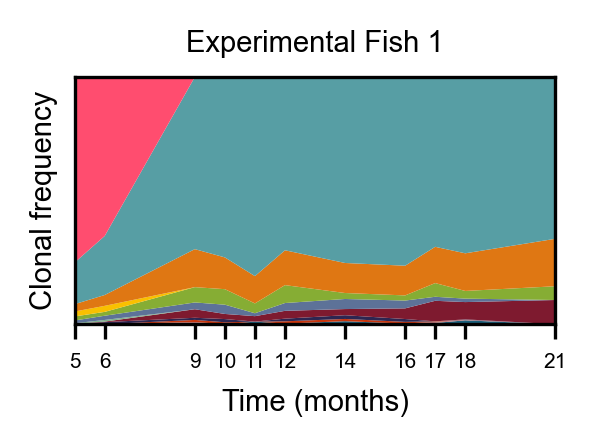

In [11]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(figsize = (2, 1.5), dpi=300)
tm.visualize.plot(fish, ax = ax)
ax.set_yticks([])
ax.set_xlabel('Time (months)')
ax.set_title('Experimental Fish 1')

plt.tight_layout()

filepath = os.path.join('images', 'fish1.svg')
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

In [15]:
df.query('scenario == @exp_scenario and fish == @fish_id')[['clone', 'r_opt', 'pass_null']]

,clone,r_opt,pass_null
38304,0,16.144047,True
38305,1,21.298320,True
38306,2,3.062160,True
38307,3,11.989106,True
38308,4,3.835728,True
38309,5,3.147120,True
38310,6,3.205129,True
38311,7,2.173425,True
38312,8,1.955534,True
38313,9,1.735043,True


## Panel 4d

In [17]:
scenarios = ['n1000_r0_y6', 'n1000_r1_y6', exp_scenario]
scenarios_labels = ['Model\n$rp=0$', 'Model\n$rp=1$', 'Exp. data']
mapping = dict(zip(scenarios, scenarios_labels))

df2 = df.query('scenario.isin(@scenarios)').copy()
df2['scenario'] = df2['scenario'].map(mapping)

overall_pass = df2.groupby('scenario', as_index = False).agg({'pass_null': 'mean'})
overall_pass['percent_pass'] = overall_pass['pass_null'] * 100
overall_pass['order'] = [2, 0, 1]
overall_pass

,scenario,pass_null,percent_pass,order
0,Exp. data,0.870036,87.003610,2
1,Model\n$rp=0$,0.025000,2.500000,0
2,Model\n$rp=1$,0.892486,89.248555,1


In [18]:
for x, label in enumerate(scenarios_labels):
    print(overall_pass.loc[x, 'percent_pass'])

87.00361010830325
2.5
89.2485549132948


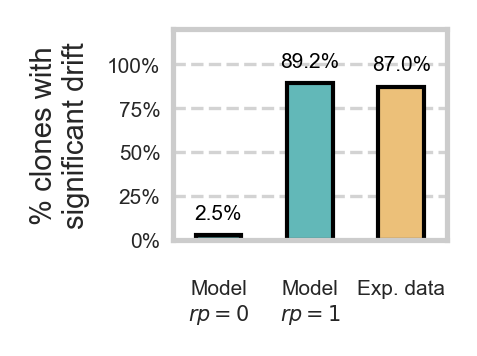

In [20]:
sns.set_theme(style = 'whitegrid')
plt.rcParams.update(small_label_settings)
plt.figure(figsize = (1.6, 1.2), dpi = 300)

palette = {
    'Model\n$rp=0$': hue(0),
    'Model\n$rp=1$': hue(1),
    'Exp. data': '#ffc566'
}

ax = sns.barplot(
    data=overall_pass, x='scenario', y='percent_pass',
    edgecolor='black', hue='scenario', palette=palette, legend=False,
    width = 0.5, order = ['Model\n$rp=0$', 'Model\n$rp=1$', 'Exp. data']
)

# Grid styling
ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis = 'y')

plt.ylabel("% clones with\nsignificant drift")
plt.xlabel('')
plt.xticks(rotation=0, ha='center')

for i, row in overall_pass.iterrows():
    x = row['order']
    percent_pass = row['percent_pass']
    ax.annotate(
        f'{percent_pass:.1f}%',
        (x, percent_pass),
        ha = 'center', va = 'bottom',
        fontsize = 5, color = 'black', xytext = (0, 3),
        textcoords = 'offset points'
    )

ax.set_ylim(0, 120)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.tick_params(axis='y', pad = -3)
ax.set_yticks([0, 25, 50, 75, 100])

plt.tight_layout()

filepath = os.path.join('images', 'null_hypothesis.svg')
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

## Panel 4e

In [21]:
sim_scenario = 'n1000_r1_y6'

df2 = df.query('scenario == @exp_scenario').copy()

# Fit logistic regression
X = sm.add_constant(df2['last_time'])
y = df2['pass_null']
model = sm.Logit(y, X).fit()

print(model.summary())

last_time = model.params['last_time']
p = model.pvalues['last_time']
print(f'\nThe coefficient of last_time is {last_time:.3f} with p={p:.2e}.')

Optimization terminated successfully.
         Current function value: 0.358308
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              pass_null   No. Observations:                  277
Model:                          Logit   Df Residuals:                      275
Method:                           MLE   Df Model:                            1
Date:                Tue, 16 Dec 2025   Pseudo R-squ.:                 0.07250
Time:                        12:23:12   Log-Likelihood:                -99.251
converged:                       True   LL-Null:                       -107.01
Covariance Type:            nonrobust   LLR p-value:                 8.175e-05
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0119      0.509      0.023      0.981      -0.985       1.009
last_time      0.1306      0.

In [22]:
# Generate a grid of last_time values across the observed range
x_vals = np.linspace(4, 28, 200)
X_pred = sm.add_constant(x_vals)

# Predicted probabilities from the logistic model
y_pred = model.predict(X_pred)

# --- Compute confidence intervals ---
# Get covariance matrix of parameters
cov = model.cov_params()
params = model.params.values

# Linear predictor and its variance
lin_pred = X_pred @ params
var_lin_pred = np.sum((X_pred @ cov) * X_pred, axis=1)
se_lin_pred = np.sqrt(var_lin_pred)

# 95% CI on logit scale, then transform back to probability
logit_lower = lin_pred - 1.96 * se_lin_pred
logit_upper = lin_pred + 1.96 * se_lin_pred
ci_lower = 1 / (1 + np.exp(-logit_lower))
ci_upper = 1 / (1 + np.exp(-logit_upper))

3 20


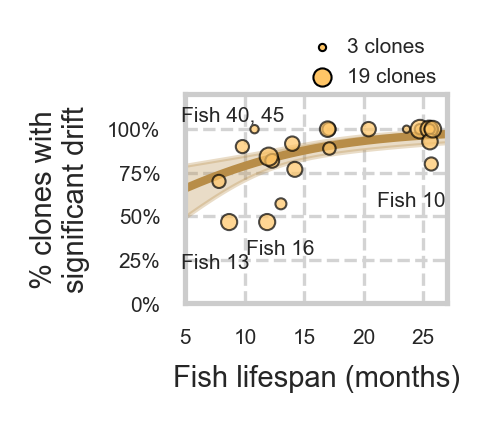

In [23]:
plt.rcParams.update(small_label_settings)
fig, ax = plt.subplots(figsize = (1.6, 1.4), dpi = 300)

agg = df2.groupby(['fish']).agg({'pass_null': 'mean', 'max_time': 'first', 'clone': 'count'})
agg['pass_null'] = agg['pass_null'] * 100
print(agg['clone'].min(), agg['clone'].max())

rng = np.random.default_rng()
x_jittered = agg['max_time'] + rng.uniform(-0.25, 0.25, size=len(agg))
ax.scatter(x_jittered, agg['pass_null'], color = '#ffc566',
    edgecolors='black',       # stroke color
    linewidths=0.5,           # stroke thickness
     zorder=5,
    s = agg['clone'],
          alpha = 0.7)
# Logistic fit
ax.plot(x_vals, 100*y_pred, color="#b88d48", linewidth=2, label="Logit fit")

# Confidence interval band
ax.fill_between(x_vals, 100*ci_lower, 100*ci_upper, color="#b88d48", alpha=0.3, label="95% CI")
ax.set_xlabel('Fish lifespan (months)')
ax.set_ylabel('% clones with\nsignificant drift')

ax.set_ylim(0, 120)
ax.set_xlim(5, 27)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xticks([5, 10, 15, 20, 25])

# Custom legend handles as before
sizes = [3, 19]
legend_handles = [
    plt.scatter([], [], s=size, color='#ffc566',
                edgecolors='black', linewidths=0.5)
    for size in sizes
]

leg = ax.legend(
    legend_handles,
    [f"{size} clones" for size in sizes],
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.7, 0.95),  # adjust horizontal position
    ncol=1,
    fontsize=5,
    handletextpad=0.2
)

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')

ax.text(13, 28, 'Fish 16', fontsize=5, ha='center')
ax.text(7.5, 20, 'Fish 13', fontsize=5, ha='center')
ax.text(24, 56, 'Fish 10', fontsize=5, ha='center')
ax.text(9, 105, 'Fish 40, 45', fontsize=5, ha='center')

ax.yaxis.set_tick_params(pad=0)   # smaller pad brings labels closer
ax.xaxis.set_tick_params(pad=0)   # smaller pad brings labels closer

plt.tight_layout()
plt.savefig('images/lifespan_null.svg', bbox_inches = 'tight', pad_inches = 0)

## Panel 5a

In [26]:
# Define mapping from scenario string to numeric r
scenario_map = {
    'n1000_r0.5_y6_realistic': 'Model\n$rp=1$',
    'n1000_r1.5_y6_realistic': 'Model\n$rp=4$',
    'n1000_r3_y6_realistic': 'Model\n$rp=15$',
    'n1000_r8_y6_realistic': 'Model\n$rp=36$',
    exp_scenario: 'Exp. data'
}

df_plot = df.query('scenario.isin(@scenario_map.keys())').copy()
df_plot = df_plot.query('(scenario == @exp_scenario) | (fish < 24)').copy()
df_plot['scenario_label'] = df_plot['scenario'].map(scenario_map)

palette = {
    'Model\n$rp=1$': hue(1),
    'Model\n$rp=4$': hue(4),
    'Model\n$rp=15$': hue(15),
    'Model\n$rp=36$': hue(36),
    'Exp. data': exp_hue
}

order = ['Exp. data', 'Model\n$rp=1$', 'Model\n$rp=4$', 'Model\n$rp=15$', 'Model\n$rp=36$']

zero_counts = df_plot.groupby('scenario')['r_opt'].apply(lambda x: (x==0).mean()*100)

2.0043213737826426
[0.67851744 0.69635671 0.71507072 0.73434541 1.26565459 1.28492928
 1.30364329 1.32148256]
2.603144372620182
[1.76483077 1.79538608 2.20461392 2.23516923]
3.1763806922432702
[2.93455973 2.94733417 3.05266583 3.06544027]
3.556423121371285
[3.94925047 3.96350261 4.03649739 4.05074953]


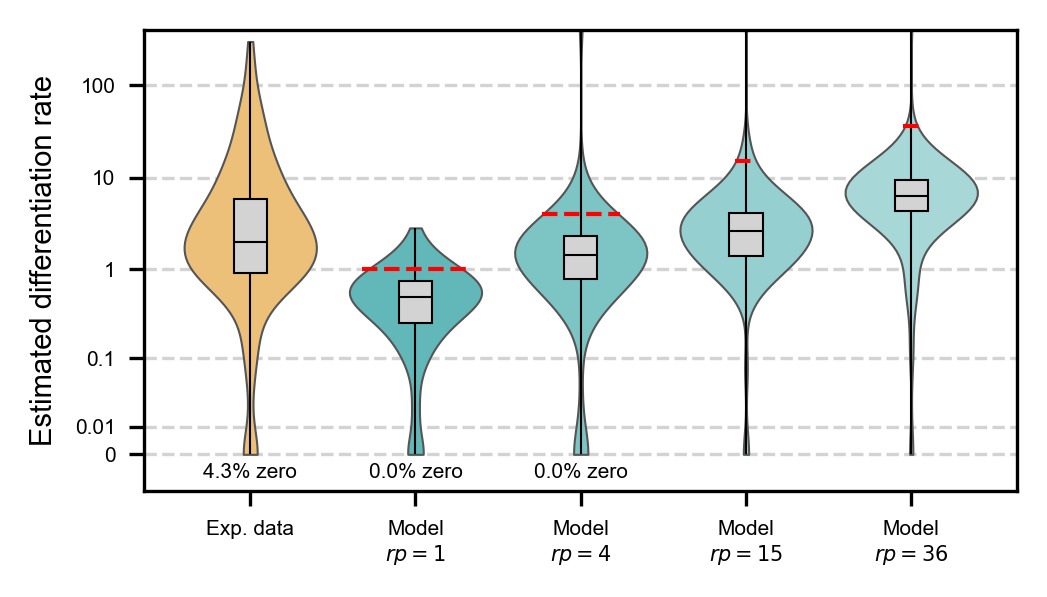

In [28]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(figsize = (3.5, 2), dpi = 300)    

sns.violinplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    inner=None, cut=0, hue='scenario_label',
    density_norm='area', linewidth=0.5, palette=palette, ax=ax, legend=False
)

sns.boxplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    whis=np.inf, width=0.2, showcaps=False,
    boxprops={'facecolor':'lightgray', 'edgecolor':'black', 'linewidth':0.5},
    whiskerprops={'color':'black', 'linewidth':0.5},
    capprops={'color':'black', 'linewidth':0.5},
    medianprops={'color':'black', 'linewidth':0.5},
    ax=ax
)

# "True" r values in red dashed lines
for i, r in enumerate([1, 4, 15, 36]):
    col = i + 1
    y_val = symlog10(r, linthresh=1e-2)     
    print(y_val)
    
    poly = ax.collections[col]
    verts = poly.get_paths()[0].vertices
    mask = np.isclose(verts[:,1], y_val, atol=0.05)  # tolerance around y_val
    x_coords = verts[mask,0]
    print(x_coords)
    
    xmin, xmax = x_coords.min(), x_coords.max()
    ax.hlines(
        y_val, xmin, xmax, colors='red', linestyles='dashed', linewidth=1
    )

# Annotations with pertentage of clones that are zero.
pct = zero_counts.get(exp_scenario, 0)
ax.text(0, -0.2, f"{pct:.1f}% zero",
        ha='center', va='center', fontsize=5)

pct = zero_counts.get('n1000_r1_y6', 0)
ax.text(1, -0.2, f"{pct:.1f}% zero",
        ha='center', va='center', fontsize=5)

pct = zero_counts.get('n1000_r4_y6', 0)
ax.text(2, -0.2, f"{pct:.1f}% zero",
        ha='center', va='center', fontsize=5)

ax.set_xlabel('')

# Set y ticks.
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax.set_yticks(tick_symlog)
ax.set_yticklabels([str(r) for r in tick_r])
ax.set_ylim([-0.4, 4.6])
ax.set_ylabel('Estimated differentiation rate')

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')
ax.set_axisbelow(True) 

plt.tight_layout()
plt.savefig('./images/violin.svg', bbox_inches = 'tight', pad_inches = 0)

## Panel 5b

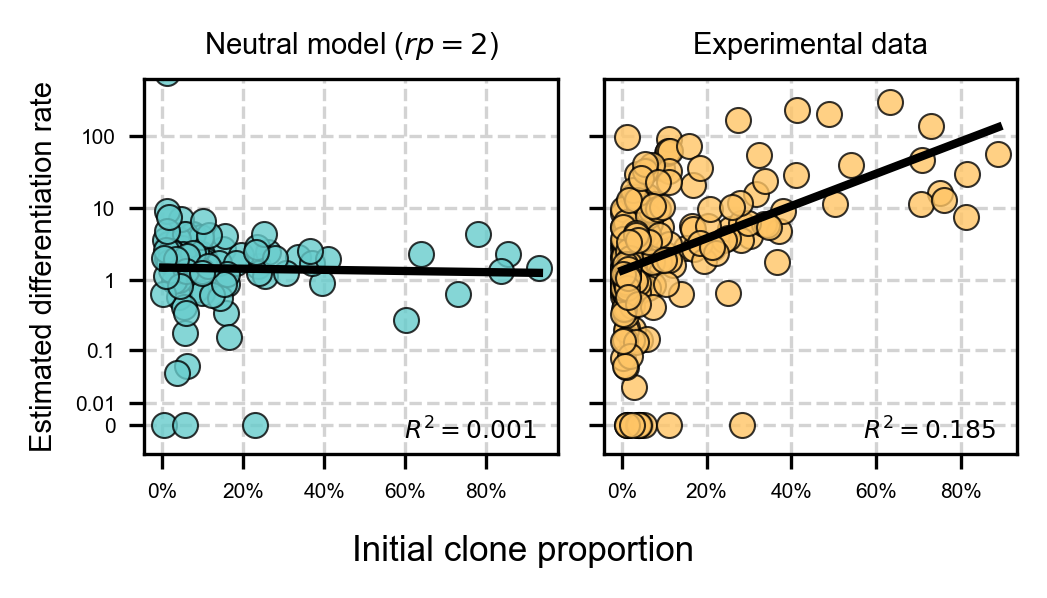

In [30]:
exp_scenario = 'full_pipeline'
sim_scenario = 'n1000_r2_y6_realistic'

dep_var = 'symlog10_r'

df2 = df if dep_var != 'log10_r' else df[df['r_opt'] > 1e-8].copy()

exp_df = df2.query('scenario == @exp_scenario and ~r_opt.isna()').copy()
sim_df  = df2.query('scenario == @sim_scenario and ~r_opt.isna() and fish < 30').copy()

# Fit regressions
slope_exp, intercept_exp, r_exp, p_exp, stderr_exp = linregress(exp_df['init_freq'], exp_df[dep_var])
slope_sim, intercept_sim, r_sim, p_sim, stderr_sim = linregress(sim_df['init_freq'], sim_df[dep_var])

# X values for smooth line
x_exp = np.linspace(exp_df['init_freq'].min(), exp_df['init_freq'].max(), 200)
x_sim = np.linspace(sim_df['init_freq'].min(), sim_df['init_freq'].max(), 200)

# Predicted values
y_exp = intercept_exp + slope_exp * x_exp
y_sim = intercept_sim + slope_sim * x_sim

# Plot
fig, axes = plt.subplots(1, 2, figsize=(3.5, 2), dpi = 300, sharey=True)

palette = {
    'Model\n$rp=0$': hue(0),
    'Model\n$rp=1$': hue(1),
    'Exp. data': exp_hue
}

# Grid styling
for ax in axes:
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax.set_axisbelow(True) 

line_color = 'black'

# Simulation scenario
axes[0].scatter(sim_df['init_freq'], sim_df[dep_var], color = hue(2.5), alpha=0.8, edgecolor="black", linewidth=0.5)
axes[0].plot(x_sim, y_sim, color=line_color, linewidth=2)
axes[0].set_title("Neutral model ($rp=2$)")
axes[0].set_ylabel("Estimated differentiation rate")

# Experimental scenario
axes[1].scatter(exp_df['init_freq'], exp_df[dep_var], color = exp_hue, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[1].plot(x_exp, y_exp, color=line_color, linewidth=2)
axes[1].set_title('Experimental data')

# Y-axis ticks
if dep_var == 'log10_r':
    tick_r = [1e-2, 1e-1, 1, 10, 100]
    tick_symlog = np.log10(np.array(tick_r))
    axes[0].set_ylim([-2.5, 2.8])
elif dep_var == 'symlog10_r':
    tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
    tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
    axes[0].set_ylim([-0.4, 4.8])
axes[0].set_yticks(tick_symlog)
axes[0].set_yticklabels([str(r) for r in tick_r])


axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

fig.supxlabel("Initial clone proportion", y=0.05)

# Annotate R^2 values at bottom right of each axis
axes[0].text(0.95, 0.025, f"$R^2 = {r_sim**2:.3f}$",
             transform=axes[0].transAxes, ha='right', va='bottom', fontsize=6)
axes[1].text(0.95, 0.025, f"$R^2 = {r_exp**2:.3f}$",
             transform=axes[1].transAxes, ha='right', va='bottom', fontsize=6)

plt.tight_layout()
plt.savefig('./images/correlation.svg', bbox_inches = 'tight', pad_inches = 0)

In [31]:
# df_hypothesis = df.query('~r_median.isna() and r_median > 0 and scenario in ["real", "n1000_r2.5_y6"]')
df_hypothesis = df[
    (df['scenario'] == exp_scenario) |
    ((df['scenario'] == sim_scenario) & (df['fish'] < 24))
].copy()

# df_hypothesis = df_hypothesis[df_hypothesis['r_opt'] > 0]

# Set scenario as categorial and re-order.
df_hypothesis['scenario'] = pd.Categorical(df_hypothesis['scenario'])
df_hypothesis['scenario'] = df_hypothesis['scenario'].cat.reorder_categories(
    [sim_scenario, exp_scenario]
)

# Center data
df_hypothesis['init_freq_c'] = df_hypothesis['init_freq'] - df_hypothesis['init_freq'].mean()
df_hypothesis['log_r_c']     = df_hypothesis['symlog10_r']      - df_hypothesis['symlog10_r'].mean()

model = smf.ols("log_r_c ~ init_freq * scenario", data = df_hypothesis).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                log_r_c   R-squared:                       0.165
Model:                            OLS   Adj. R-squared:                  0.158
Method:                 Least Squares   F-statistic:                     24.24
Date:                Tue, 16 Dec 2025   Prob (F-statistic):           2.45e-14
Time:                        12:24:35   Log-Likelihood:                -400.71
No. Observations:                 372   AIC:                             809.4
Df Residuals:                     368   BIC:                             825.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

In [32]:
model.aic

np.float64(809.4154268150676)

In [33]:
print(f'The significance of initial frequency on simulated data is {model.pvalues.values[2]:.2e}.')
print(f'The significance of initial frequency on real data is {model.pvalues.values[3]:.2e}.')

The significance of initial frequency on simulated data is 8.37e-01.
The significance of initial frequency on real data is 7.53e-07.


In [52]:
df_hypothesis = df_hypothesis[~df_hypothesis['r_opt'].isna()].copy().reset_index(drop=True)

In [54]:
# Mixed effects model: random intercepts for fish
model = smf.mixedlm(
    "log_r_c ~ init_freq_c * scenario",   # fixed effects
    data=df_hypothesis,
    groups=df_hypothesis["fish"]          # random intercept grouping
).fit(reml=False)

print(model.summary())

                     Mixed Linear Model Regression Results
Model:                     MixedLM         Dependent Variable:         log_r_c  
No. Observations:          372             Method:                     ML       
No. Groups:                24              Scale:                      0.4372   
Min. group size:           4               Log-Likelihood:             -390.0245
Max. group size:           28              Converged:                  Yes      
Mean group size:           15.5                                                 
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             -0.075    0.098 -0.762 0.446 -0.267  0.117
scenario[T.full_pipeline]              0.167    0.086  1.941 0.052 -0.002  0.336
init_freq_c                           -0.240    0.

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


In [55]:
# All p-values
print(model.pvalues)

Intercept                                4.461181e-01
scenario[T.full_pipeline]                5.229992e-02
init_freq_c                              4.938459e-01
init_freq_c:scenario[T.full_pipeline]    2.247918e-08
Group Var                                6.749069e-02
dtype: float64


In [56]:
model.aic

np.float64(792.0489638651197)

In [64]:
# df_hypothesis2 = df_hypothesis.query('scenario == "full_pipeline"')

model = smf.mixedlm(
    "log_r_c ~ init_freq_c * scenario",
    data=df_hypothesis,
    groups=df_hypothesis["fish"],
    re_formula="~init_freq_c"
).fit(reml=True, method="lbfgs")

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)


In [65]:
model.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                     Mixed Linear Model Regression Results
================================================================================
Model:                     MixedLM         Dependent Variable:         log_r_c  
No. Observations:          372             Method:                     REML     
No. Groups:                24              Scale:                      0.4353   
Min. group size:           4               Log-Likelihood:             -395.2962
Max. group size:           28              Converged:                  Yes      
Mean group size:           15.5                                                 
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             -0.070    0.106 -0.666 0.505 -0.277  0.137
scenario[T.full_pipeline]              0.165    0.087  1.898 0.058 -0.005  0.336
init_freq_c                           -0.215    0.391 -0.549 0.583 -0.982  0.552
init_freq_c:scenario[T.full_pipeline]  2.369    0.423  5.598 0.000  1.540  3.199
Group Var                              0.119    0.152                           
Group x init_freq_c Cov                0.039    0.328                           
init_freq_c Var                        0.136                                    
================================================================================

"""

In [63]:
model.aic

np.float64(797.4609504265627)

In [555]:
rs = [0.5, 1, 1.5, 2, 2.5, 3, 4, 5]
rows = []

for r in rs:
    sim_scenario = f'n1000_r{r}_y6_realistic'
    
    # df_hypothesis = df[
    #     (df['scenario'] == exp_scenario) |
    #     ((df['scenario'] == sim_scenario) & (df['fish'] < 24))
    # ].copy()

    df_hypothesis = df[
        (df['scenario'] == exp_scenario) |
        (df['scenario'] == sim_scenario)
    ].copy()

    # df_hypothesis = df_hypothesis[df_hypothesis['r_opt'] > 0]
    
    # Set scenario as categorial and re-order.
    df_hypothesis['scenario'] = pd.Categorical(df_hypothesis['scenario'])
    df_hypothesis['scenario'] = df_hypothesis['scenario'].cat.reorder_categories(
        [sim_scenario, exp_scenario]
    )

    # Center data
    df_hypothesis['init_freq_c'] = df_hypothesis['init_freq'] - df_hypothesis['init_freq'].mean()
    df_hypothesis['log_r_c']     = df_hypothesis['symlog10_r']      - df_hypothesis['symlog10_r'].mean()

    # [TODO] REMOVE THIS EVENTUALLY
    df_hypothesis = df_hypothesis[~df_hypothesis['log_r_c'].isna()].copy()
    
    # Mixed effects model: random intercepts for fish
    model = smf.mixedlm(
        "log_r_c ~ init_freq_c * scenario",   # fixed effects
        data=df_hypothesis,
        groups=df_hypothesis["fish"]          # random intercept grouping
    ).fit(reml=False)
    
    summary = model.summary()
    
    # Collect results for this r
    row = {"r": r}
    for term in ['init_freq_c', 'scenario[T.full_pipeline]', 'init_freq_c:scenario[T.full_pipeline]']:
        coef = model.params[term]
        pval = model.pvalues[term]
        row[term] = f"{coef:.3f} (p={pval:.3g})"
    
    # row['converged'] = model.converged

    rows.append(row)

# Build DataFrame
results_df = pd.DataFrame(rows)
results_df.set_index("r", inplace=True)

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


In [558]:
rename_dict = {
    "init_freq_c": "Centered Initial Frequency",
    "scenario[T.full_pipeline]": "Scenario (full_pipeline)",
    "init_freq_c:scenario[T.full_pipeline]": "Interaction (Init Freq × Scenario)",
    # 'converged': 'Converged'
}

results_df = results_df.rename(columns=rename_dict)

In [559]:
results_df

,Centered Initial Frequency,Scenario (full_pipeline),Interaction (Init Freq × Scenario)
r,,,
0.5,-0.140 (p=0.588),0.868 (p=5.97e-46),2.309 (p=7.14e-11)
1.0,0.008 (p=0.977),0.609 (p=1.97e-23),2.180 (p=1.26e-09)
1.5,-0.261 (p=0.361),0.357 (p=1.33e-07),2.450 (p=1.97e-10)
2.0,-0.022 (p=0.934),0.190 (p=0.00538),2.229 (p=1.66e-09)
2.5,-0.416 (p=0.159),0.071 (p=0.325),2.591 (p=6.84e-11)
3.0,-0.284 (p=0.324),0.001 (p=0.992),2.432 (p=6.62e-11)
4.0,-0.003 (p=0.991),-0.009 (p=0.901),2.203 (p=2.31e-09)
5.0,-0.133 (p=0.601),-0.313 (p=3.59e-06),2.296 (p=1.88e-11)


## Panel 5c

In [376]:
def make_summary(df):
    summary = (
        df.groupby("fish")["symlog10_r"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )
    summary["se"] = summary["std"] / summary["count"]**0.5
    summary["ci_low"] = summary["mean"] - 1.96 * summary["se"]
    summary["ci_high"] = summary["mean"] + 1.96 * summary["se"]
    return summary.sort_values("mean")

# Filter scenarios
df_full = df.query('scenario == @exp_scenario')
df_sim  = df.query('scenario == @sim_scenario and fish < 24')

summary_full = make_summary(df_full)
summary_sim  = make_summary(df_sim)

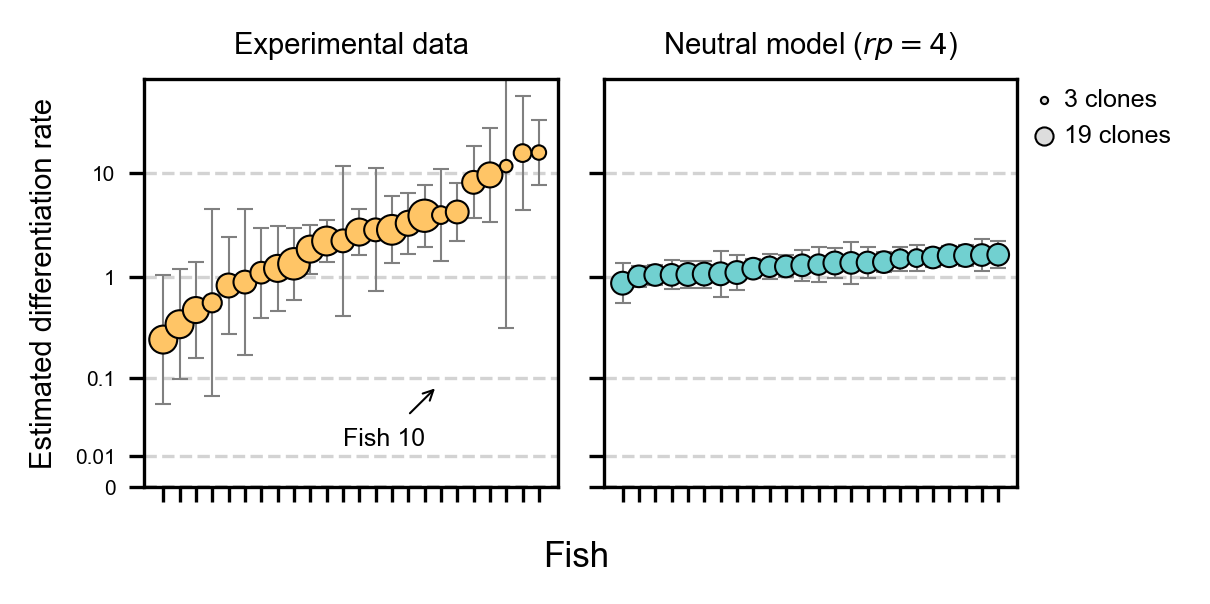

In [377]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, axes = plt.subplots(1, 2, figsize=(3.5, 2), dpi=300, sharey=True)

for ax, summary, title, color in zip(
    axes,
    [summary_full, summary_sim],
    ["Experimental data", "Neutral model ($rp=4$)"],
    [experimental_hue, hue(4)]
):
    xpos = range(len(summary))

    # Plot error bars (without markers)
    ax.errorbar(
        xpos, summary["mean"],
        yerr=[summary["mean"] - summary["ci_low"], summary["ci_high"] - summary["mean"]],
        fmt="none", ecolor="gray", capsize=2, lw = 0.5, capthick = 0.5
    )

    # Overlay scatter points with size proportional to count
    sizes = summary["count"] * 3   # scale factor, adjust as needed
    ax.scatter(
        xpos, summary["mean"],
        s=sizes, facecolor=color, edgecolor="black", zorder=3, lw = 0.5
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(title)
    # ax.set_xlabel('')
    ax.set_xticks(xpos)
    # ax.set_xticklabels(summary["fish"], size=6, rotation=90)
    ax.set_xticklabels('')
    # ax.set_xticks([])
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')

# Shared y-axis formatting
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
axes[0].set_ylabel("Estimated differentiation rate")
for ax in axes:
    ax.set_yticks(tick_symlog)
    ax.set_yticklabels([str(r) for r in tick_r])
    ax.set_ylim([0, 3.9])

axes[0].annotate(
    'Fish 10', xy=(17, 1.0), xytext=(11, 0.4), fontsize=6,
    arrowprops=dict(arrowstyle="->", color="black", lw=0.5)
)

fig.supxlabel("Fish", x=0.55, y = 0.04)

# Custom legend handles as before
sizes = [3, 19]
legend_handles = [
    plt.scatter([], [], s=size, color='#dddddd',
                edgecolors='black', linewidths=0.5)
    for size in sizes
]

leg = fig.legend(
    legend_handles,
    [f"{size} clones" for size in sizes],
    frameon=False,
    loc="center left",
    bbox_to_anchor=(0.95, 0.8),  # adjust horizontal position
    ncol=1,
    fontsize=6,
    handletextpad=-0.2
)

plt.tight_layout()
plt.savefig('./images/anova.svg', bbox_inches = 'tight', pad_inches = 0)

In [334]:
# Subset the data
group1 = df_plot.loc[df_plot['scenario'] == experimental_scenario, 'log_r']
group2 = df_plot.loc[df_plot['scenario'] == 'n1000_r4_y6', 'log_r']

# Remove NaNs and -inf
group1 = group1[~group1.isna() & (group1 != -np.inf)]
group2 = group2[~group2.isna() & (group2 != -np.inf)]

# Kolmogorov–Smirnov test (two-sample)
ks_stat, ks_pval = ks_2samp(group1, group2)

# Levene’s test (variance comparison, robust to non-normality)
lev_stat, lev_pval = levene(group1, group2)

# Variances
var1 = group1.var(ddof=1)  # sample variance
var2 = group2.var(ddof=1)

print("Kolmogorov–Smirnov test:")
print(f"  Statistic = {ks_stat:.4f}, p-value = {ks_pval:.4g}")

print("\nLevene’s test for equal variances:")
print(f"  Statistic = {lev_stat:.4f}, p-value = {lev_pval:.4g}")

print("\nSample variances:")
print(f"  Group1 variance = {var1:.4f}")
print(f"  Group2 variance = {var2:.4f}")

Kolmogorov–Smirnov test:
  Statistic = 0.2412, p-value = 9.505e-06

Levene’s test for equal variances:
  Statistic = 27.3291, p-value = 2.734e-07

Sample variances:
  Group1 variance = 7.6446
  Group2 variance = 0.4483


In [74]:
# Subset to scenario == "real"
group2 = df.loc[(df['scenario'] == 'full_pipeline') & (df['r_opt'] > 0), ['r_opt', 'fish']]
# group2 = df.loc[(df['scenario'] == 'real') & (df['r_median'] > 0), ['r_median', 'fish']]
group2['log_r'] = np.log(group2['r_opt'])

# Overall mean
grand_mean = group2['log_r'].mean()

# Group means and sizes
group_stats = group2.groupby('fish')['log_r'].agg(['mean', 'count'])

# --- Between-group variance ---
# Weighted variance of group means around the grand mean
between_var = (group_stats['count'] * (group_stats['mean'] - grand_mean)**2).sum() / (group_stats['count'].sum() - 1)

# --- Within-group variance ---
# Pooled variance across groups
within_var = group2.groupby('fish').apply(lambda g: g['log_r'].var(ddof=1) * (len(g)-1), include_groups = False).sum() / (len(group2) - len(group_stats))

print("Between-group variance:", between_var)
print("Within-group variance:", within_var)

Between-group variance: 1.2198654590113185
Within-group variance: 6.906444565266333


In [82]:
df_anova = df.query('scenario.isin(["full_pipeline", "n1000_r4_y6"])').copy()
# df_anova['log_r'] = df_anova['r_opt']
df_anova['symlog_r'] = symlog10(df_anova['r_opt'])

In [83]:
# Assume df has columns: scenario, fish, log_r

# Treat fish as nested within scenario
df_anova['scenario'] = df['scenario'].astype('category')
df_anova['fish'] = df['fish'].astype('category')

# Build model: log_r ~ scenario + fish(scenario)
# In statsmodels, nesting is written as C(fish):C(scenario)
model = ols('symlog_r ~ C(scenario) + C(fish):C(scenario)', data=df_anova).fit()

anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 47, but rank is 0
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/base/model.py:1923: RuntimeWarning: invalid value encountered in divide
  F /= J


KeyboardInterrupt: 

In [76]:
model = ols('log_r ~ C(fish)', data=group2).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

               sum_sq     df         F    PR(>F)
C(fish)    323.264347   23.0  2.035052  0.004443
Residual  1671.359585  242.0       NaN       NaN
